U fajlu “guardian_news_subset.csv” su dati podaci o novinskim tekstovima koje je objavljivao britanski list Guardian u toku nekoliko godina. Fajl sadrzi vise kolona (varijabli) od kojih su za ovaj zadatak relevantne samo kolone webTitle i bodyContent.

Koristeci podatke iz navedenog fajla, potrebno je uraditi sledece:
- Kreirati novu kolonu `articleText` koja objedinjuje sadrzaj kolona webTitle i bodyContent (kroz obicno nadovezivanje stringova).
- Transformisati sadrzaj kolone articleText u `vektorsku` (tj numericku) reprezentaciju primenom pristupa zasnovanom na vektorima reci (word vectors), i konkretno vektorima reci raspolozivim u okviru `spaCy medium modela`.
- Izvrsiti klasterizaciju (transformisanih) novinskih tekstova primenom `aglomerativnog hijerarhijskog klasterovanja`. Odrediti optimalni broj klastera na osnovu `dendrograma i siluet skora` (silhouette score). `Obrazloziti` izbor optimalnog broja klastera.
- Za svaki od klastera odrediti `top 10 reci` / izraza na osnovu `TF-IDF` metrike.
- Odrediti `velicinu` svakog od klastera i `opisati` svaki klaster na osnovu identifikovanih top 10 reci/izraza, i eventualnog uvida u naslove/sadrzaj clanaka u okviru klastera.

In [1]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.base import BaseEstimator, TransformerMixin

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch

import matplotlib.pyplot as plt

from pathlib import Path

import spacy

In [2]:
RAND_STATE = 1

SPACY_MODEL = 'en_core_web_md'

#### UCITAVANJE I PREGLED PODATAKA

In [3]:
data = pd.read_csv(Path.cwd() / 'data' / 'guardian_news_subset.csv')

data.head()

,id,webTitle,bodyContent,webPublicationDate
0,17349,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,2016-09-24T19:05:52Z
1,17858,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",2016-10-30T07:30:02Z
2,60943,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,2018-08-26T07:00:07Z
3,118230,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,2021-02-24T13:00:18Z
4,21992,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,2016-12-27T18:07:27Z


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  2500 non-null   int64 
 1   webTitle            2500 non-null   object
 2   bodyContent         2483 non-null   object
 3   webPublicationDate  2500 non-null   object
dtypes: int64(1), object(3)
memory usage: 78.3+ KB


In [5]:
data.duplicated().sum()

np.int64(0)

Postoji odredjen broj NA vrednosti -> takve redove cemo izbaciti.

In [6]:
data.dropna(inplace=True)

data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2483 entries, 0 to 2499
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   id                  2483 non-null   int64 
 1   webTitle            2483 non-null   object
 2   bodyContent         2483 non-null   object
 3   webPublicationDate  2483 non-null   object
dtypes: int64(1), object(3)
memory usage: 97.0+ KB


In [7]:
data.isna().sum().sum()

np.int64(0)

#### KRERIANJE NOVE KOLONE

In [8]:
data['articleText'] = data.apply(lambda row: f"{row.webTitle}. {row.bodyContent}", axis=1)

data[['webTitle', 'bodyContent', 'articleText']].head()

,webTitle,bodyContent,articleText
0,John Prine review – legendary songwriter looks...,John Prine walked onstage around 10.40pm Thurs...,John Prine review – legendary songwriter looks...
1,Nigel Kennedy; Oxford lieder festival; London ...,"Identity and dispossession cast long shadows, ...",Nigel Kennedy; Oxford lieder festival; London ...
2,The week in classical: BBC Proms 49 & 51; Lond...,We are a timorous nation when presented with “...,The week in classical: BBC Proms 49 & 51; Lond...
3,"Archie Shepp on jazz, race and freedom: 'Insti...",One night at Five Spot Cafe in the early 1960s...,"Archie Shepp on jazz, race and freedom: 'Insti..."
4,'He was my inspiration': fans flock to George ...,George Michael fans have flocked to Highgate i...,'He was my inspiration': fans flock to George ...


In [9]:
data['wordCount'] = data.articleText.apply(lambda x: len(x.split()))

data.wordCount.describe()

count    2483.000000
mean      803.726540
std       569.189889
min        67.000000
25%       445.000000
50%       698.000000
75%       987.000000
max      7277.000000
Name: wordCount, dtype: float64

Ogranicicemo da su novinski tekstovi duzine `400` reci, kako bi dalje analize bile krace.

In [10]:
def reduce_word_count(text):
    return text if len(text.split()) <= 400 else " ".join(text.split()[:400])


data['articleTextReduced'] = data.articleText.apply(reduce_word_count)

data.wordCount = data.articleTextReduced.apply(lambda x: len(x.split()))
data.wordCount.describe()

count    2483.000000
mean      376.239629
std        60.248032
min        67.000000
25%       400.000000
50%       400.000000
75%       400.000000
max       400.000000
Name: wordCount, dtype: float64

#### EMBEDDINGS

In [11]:
class CustomTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, spacy_pipeline, vector_dim=300):
        self.spacy_pipeline = spacy_pipeline
        self.vector_dim = vector_dim

    def fit(self, X, y=None):
        return self

    def spacy_tokenizer(self, doc):
        tokens = self.spacy_pipeline(doc)
        tokens = [token for token in tokens
                  if ((not token.is_punct) and (not token.is_space) and (not token.like_num)
                      and (not token.like_url) and (not token.is_stop))]
        words = [token.lemma_.lower() for token in tokens]
        return words

    def transform(self, X):
        X_transformed = np.zeros((len(X), self.vector_dim))
        for i, text in enumerate(X):
            words = self.spacy_tokenizer(text)
            X_transformed[i] = self.spacy_pipeline(" ".join(words)).vector
        return X_transformed

In [12]:
spacy_model = spacy.load(SPACY_MODEL, disable=['parser', 'ner'])

review_transformer = CustomTransformer(spacy_pipeline=spacy_model)

review_embeddings = review_transformer.fit_transform(X=data.articleTextReduced)

review_embeddings.shape

(2483, 300)

#### KOSINUSNA SLICNOST

In [13]:
review_simmilarities = cosine_similarity(review_embeddings, review_embeddings)

review_simmilarities.shape

(2483, 2483)

#### KOSINUSNA UDALJENOST

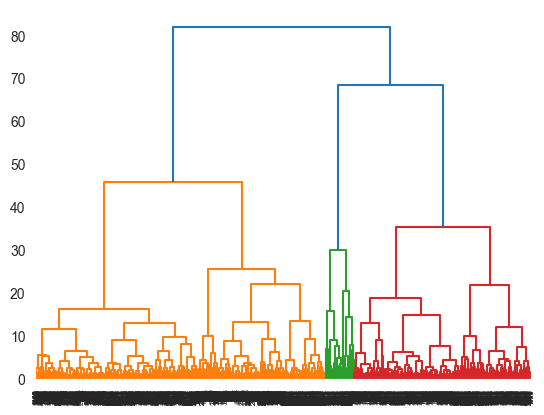

In [14]:
review_dist = 1 - review_simmilarities

ward_linkage = sch.linkage(review_dist, method='ward')

sch.dendrogram(ward_linkage)
plt.show()

Dendogram pokazuje da bi optimalan broj klastera bio izmedju `3 i 5`. Koristicemo jos jednu metriku da bismo utvrdili optimalan broj klastera.

#### SILHOUETTE SCORE

In [15]:
sil_scores = []

for k in range(3, 6):
    clust = sch.fcluster(ward_linkage, t=k, criterion='maxclust')
    # uklanjanje malih negativnih udaljenosti
    review_dist_clipped = np.clip(review_dist, a_min=0.0, a_max=None)
    score = silhouette_score(review_dist_clipped, clust, metric='precomputed', random_state=RAND_STATE)
    sil_scores.append(score)

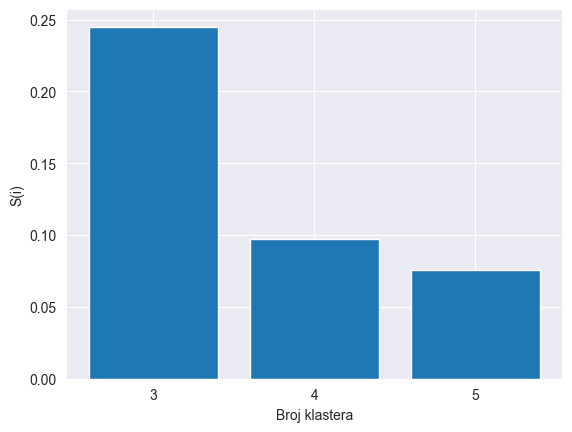

In [16]:
plt.bar(range(3, 6), sil_scores)
plt.ylabel('S(i)')
plt.xlabel('Broj klastera')
plt.xticks(range(3, 6))
plt.show()

Prosecan silhouette score je vrlo mali -> klasteri nisu dovoljno jasno radvojeni.

Silhouette score je najveci za `3 klastera` -> uradicemo ovaj zadatak sa 3 klastera.

#### KLASTERIZACIJA

In [17]:
cluster_opt = sch.fcluster(ward_linkage, t=3, criterion='maxclust')

pd.Series(cluster_opt).value_counts()

1    1453
3     887
2     143
Name: count, dtype: int64

Klasteri nemaju isti broj elemenata -> raspodela novinskih clanaka nije idealno podeljena po klasterima.

#### ODREDIVANJE KLJUCNIH RECI

In [18]:
data['cluster'] = cluster_opt

In [19]:
def spacy_tokenizer(doc):
    tokens = spacy_model(doc)
    tokens = [token for token in tokens
              if ((not token.is_punct) and (not token.is_space) and (not token.like_num)
                  and (not token.like_url) and (not token.is_stop))]
    words = [token.lemma_.lower() for token in tokens]
    return words


def get_top_ngrams(cluster_id, top_n=10, words_to_remove=None):
    tfidf_vectorizer = TfidfVectorizer(tokenizer=spacy_tokenizer, token_pattern=None, ngram_range=(1, 2), min_df=0.01,
                                       max_df=0.95)

    # svi clanci za izabran klaster
    cluster_reviews = data.loc[data.cluster == cluster_id].articleTextReduced
    # racunanje tfidf
    cluster_tfidf = tfidf_vectorizer.fit_transform(cluster_reviews)
    # izvlacenje svih ngrama
    candidate_keywords = tfidf_vectorizer.get_feature_names_out()
    # racunanje prosecne tfidf vrednosti za svaki ngram
    mean_tfidf = np.asarray(cluster_tfidf.mean(axis=0)).flatten()

    sorted_candidates = sorted([(keyword, tfidf) for keyword, tfidf in zip(candidate_keywords, mean_tfidf)],
                               key=lambda x: x[1], reverse=True)

    if words_to_remove:
        sorted_candidates = [(kw, sc) for kw, sc in sorted_candidates if kw not in words_to_remove]

    return sorted_candidates[:top_n]

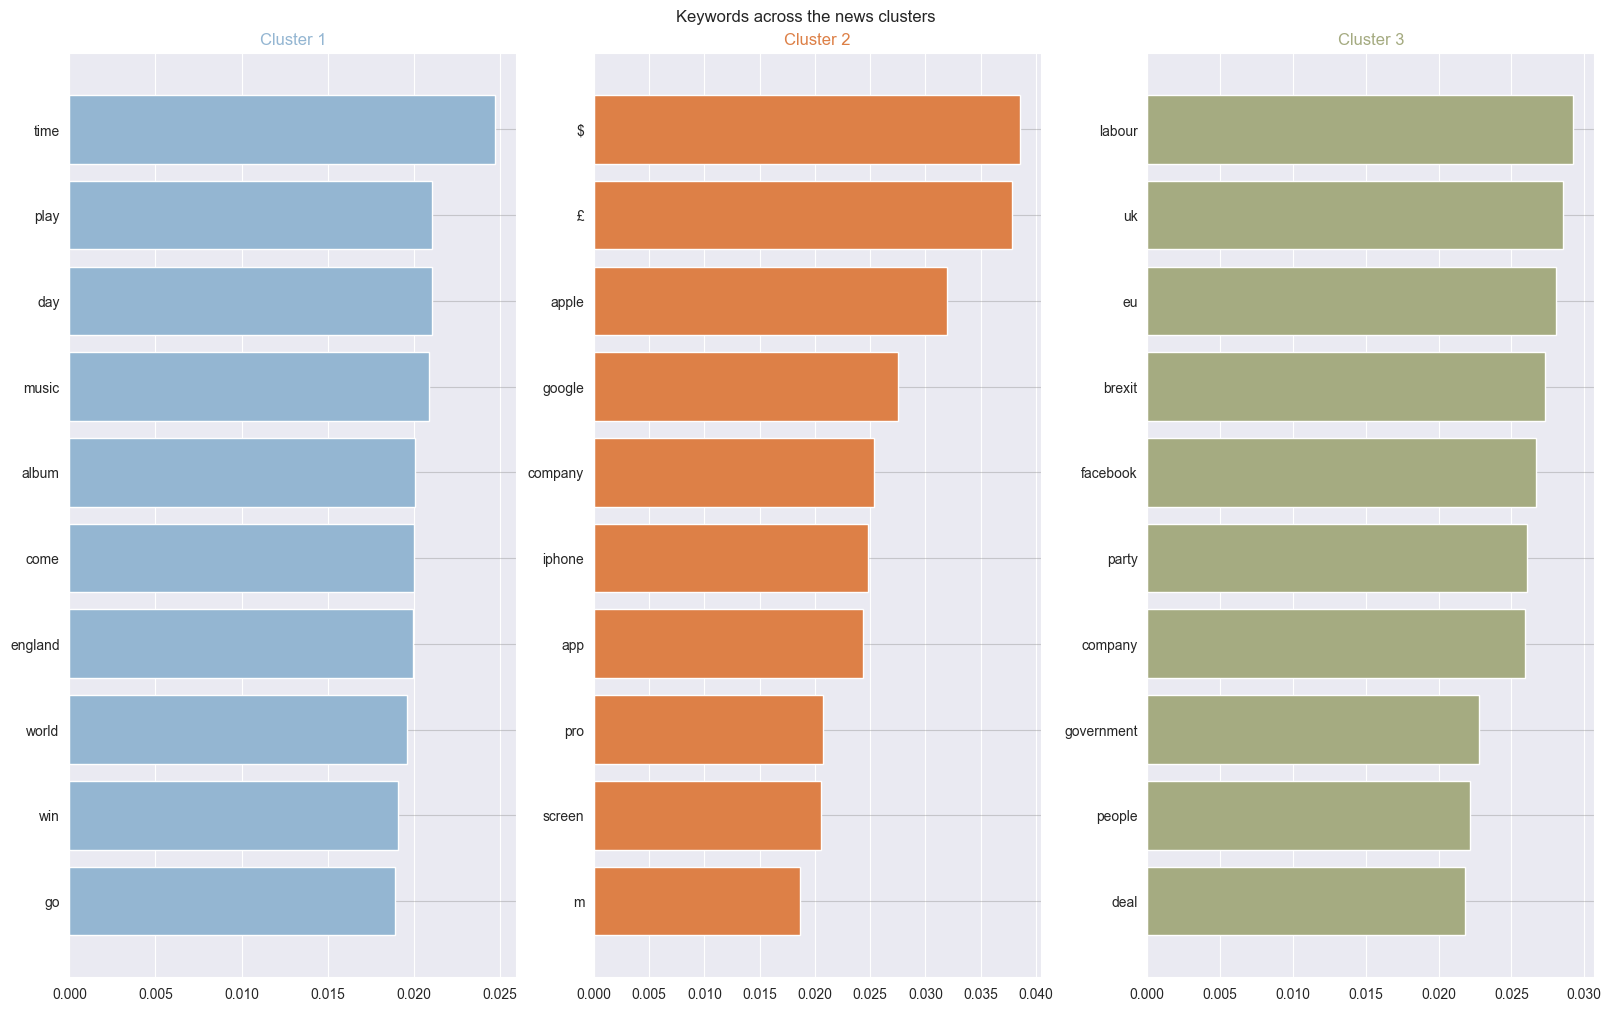

In [20]:
from pypalettes import load_cmap

fig, ax_grid = plt.subplots(nrows=1, ncols=3, figsize=(16, 10), constrained_layout=True)
axes = ax_grid.flatten()

cmap = load_cmap("excel_Median")

n_clust = data['cluster'].nunique()
for i in range(n_clust):
    scored_kwds = get_top_ngrams(i + 1,words_to_remove=['say','like','good','year','new'])
    scored_kwds = sorted(scored_kwds, key=lambda item: item[1])
    scores = [s for kw, s in scored_kwds]
    keywords = [kw for kw, s in scored_kwds]

    axes[i].barh(keywords, scores, color=cmap(i))
    axes[i].set_title(f"Cluster {i + 1}", color=cmap(i))
    axes[i].grid(visible=True, axis='y', color='gray', alpha=0.35)

fig.suptitle("Keywords across the news clusters")

plt.show()

Na osnovu kljucnih reci mozemo da grubo pretpostavimo o cemu se radi u novinskim clancima za svaki klaster:
- Klaster 1: muzika
- Klaster 2: tehnologije
- Klaster 3: politika

Ono sto je i silhouette score pokazao, a sto se moze videti i iz samih kljucnih reci, a i ako se pogledaju naslovi svakog klastera -> deluje da ima previse preklapanja tj. klasteri nisu jasno razdvojeni.